# MNIST Digit Recognizer — GA-AD: Genetic Algorithm Adaptive Dropout (revised stochastic elite-resampling prototype)

**Research Implementation of GA-AD on MNIST**

This notebook implements a **Genetic Algorithm Adaptive Dropout (revised stochastic elite-resampling prototype) (GA-AD)** framework:

- Neuron-level guidance uses absolute changes in activation gradients ($\Delta g_i$) and a polynomial derivative descriptor $C_i$.
- Combined priority score $Q_i = \alpha s_i + \beta \widehat{C}_i$ guides GA initialization and fitness.
- **Genetic Algorithm (GA)** searches for a fixed-cardinality binary neuron mask with exactly $D = \mathrm{round}(N \cdot p)$ inactive neurons, where $p$ is a **user-specified target dropout rate** (default 0.3).
- The calculus-based outer procedure for estimating $p^*$ has been **removed**; rate is fixed and only neuron identities are optimized by the GA.

### Research Questions
1. Does GA-guided selection of *which* neurons to drop (at a fixed rate) improve the generalization–sparsity trade-off vs conventional random Dropout?
2. How do gradient-change scores and polynomial derivative descriptors affect mask quality and final test performance?
3. What is the computational overhead of epoch-level GA-AD relative to standard Dropout?

### Pipeline
1. Data loading & cleaning  
2. EDA  
3. Preprocessing + stratified internal train/val/test split  
4. Baseline models (No-Dropout, Standard Dropout 0.3)  
5. Full GA-AD implementation (Modules A–C + E) applied to hidden layers  
6. Controlled comparison + learning curves + metrics  
7. Research discussion & limitations

> **Dataset:** `/kaggle/input/datasets/animatronbot/mnist-digit-recognizer/train.csv`  
> Only `train.csv` is provided → we create a rigorous internal 70/15/15 stratified split.  
> GPU recommended. This is a research prototype; full hyperparameter sweeps and multi-seed statistics are left for follow-up.


## 1. Imports & Reproducibility Setup

In [4]:
import os
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from copy import deepcopy

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_recall_fscore_support
)
from sklearn.decomposition import PCA

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks, optimizers
from tensorflow.keras.utils import to_categorical

# -----------------------------
# Reproducibility
# -----------------------------
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# GPU memory growth
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"GPU(s) available: {len(gpus)}")
    except RuntimeError as e:
        print(e)
else:
    print("Running on CPU")

print(f"TensorFlow: {tf.__version__}")
print(f"Keras: {keras.__version__}")

GPU(s) available: 2
TensorFlow: 2.21.0
Keras: 3.13.2


## 2. Load the Dataset

Only `train.csv` is available (42 000 samples, 785 columns).  
We create an internal stratified train / validation / test split.

In [5]:
TRAIN_PATH = '/kaggle/input/datasets/animatronbot/mnist-digit-recognizer/train.csv'
# Fallback common path
# TRAIN_PATH = '/kaggle/input/mnist-digit-recognizer/train.csv'

train_df = pd.read_csv(TRAIN_PATH)

print("Train shape:", train_df.shape)
print("\nFirst 5 rows:")
display(train_df.head())
print("\nLabel distribution:\n", train_df['label'].value_counts().sort_index())

Train shape: (42000, 785)

First 5 rows:


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Label distribution:
 label
0    4132
1    4684
2    4177
3    4351
4    4072
5    3795
6    4137
7    4401
8    4063
9    4188
Name: count, dtype: int64


## 3. Data Cleaning

In [6]:
print("Missing values:", train_df.isnull().sum().sum())
print("Duplicate rows:", train_df.duplicated().sum())
print("Unique labels:", sorted(train_df['label'].unique()))

pixel_cols = [c for c in train_df.columns if c != 'label']
print("Pixel value range:", train_df[pixel_cols].min().min(), "→", train_df[pixel_cols].max().max())
print("Data is clean — no imputation required.")

Missing values: 0
Duplicate rows: 0
Unique labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Pixel value range: 0 → 255
Data is clean — no imputation required.


## 4. Exploratory Data Analysis (selected)

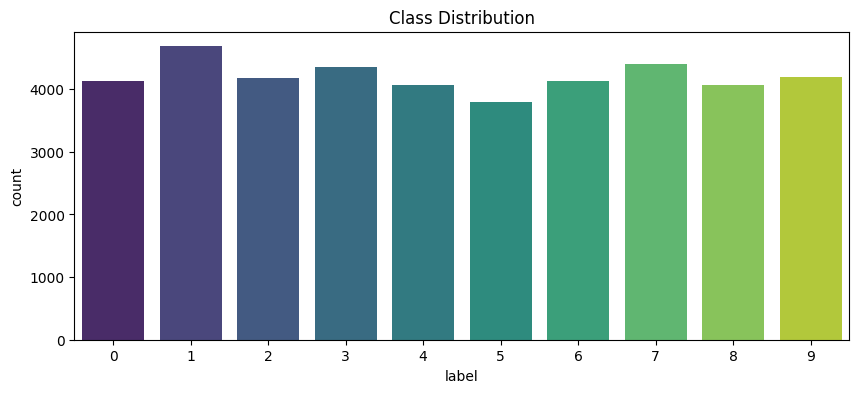

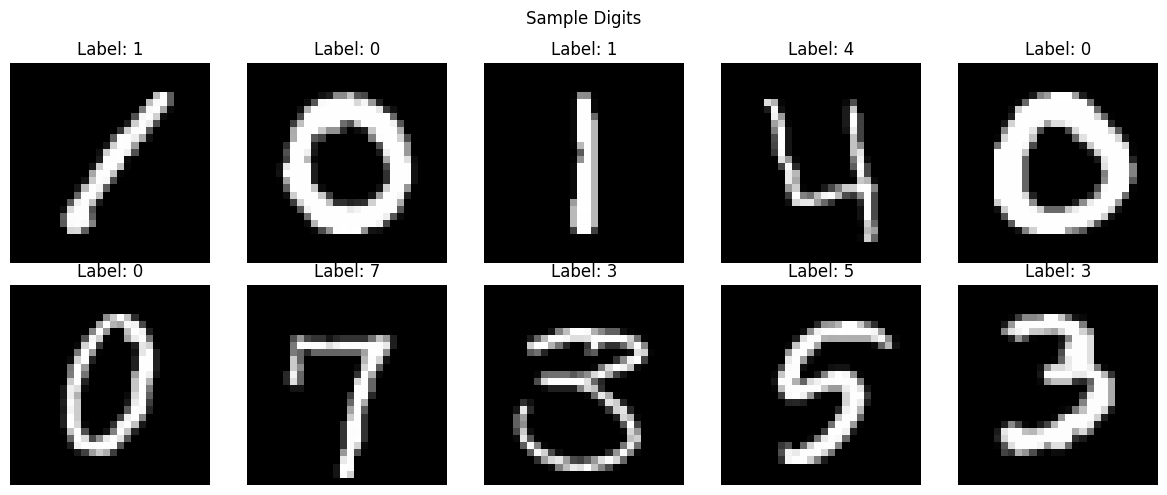

In [7]:
plt.figure(figsize=(10, 4))
sns.countplot(x='label', data=train_df, palette='viridis')
plt.title('Class Distribution')
plt.show()

def plot_sample_digits(df, n=10):
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    axes = axes.ravel()
    for i in range(n):
        img = df.iloc[i, 1:].values.reshape(28, 28)
        axes[i].imshow(img, cmap='gray')
        axes[i].set_title(f"Label: {df.iloc[i, 0]}")
        axes[i].axis('off')
    plt.suptitle('Sample Digits')
    plt.tight_layout()
    plt.show()

plot_sample_digits(train_df)

## 5. Preprocessing & Internal Split

In [8]:
X = train_df.drop('label', axis=1).values.astype('float32') / 255.0
y = train_df['label'].values
y_cat = to_categorical(y, num_classes=10)

# Outer test set is isolated until final evaluation.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y_cat, test_size=0.15, random_state=SEED, stratify=y
)
# Independent early-stopping validation set.
X_train_pool, X_val, y_train_pool, y_val = train_test_split(
    X_dev, y_dev, test_size=0.1765, random_state=SEED,
    stratify=np.argmax(y_dev, axis=1)
)
# GA fitness/selection data are held out from gradient updates and from early stopping.
X_train, X_ga_holdout, y_train, y_ga_holdout = train_test_split(
    X_train_pool, y_train_pool, test_size=0.10, random_state=SEED,
    stratify=np.argmax(y_train_pool, axis=1)
)

print(f"Train          : {len(X_train)}")
print(f"GA holdout     : {len(X_ga_holdout)}")
print(f"Early-stop val : {len(X_val)}")
print(f"Final test     : {len(X_test)}")

Train          : 26458
GA holdout     : 2940
Early-stop val : 6302
Final test     : 6300


## 6. Shared Architecture Definition

Moderately deep MLP so that overfitting is observable and the effect of adaptive regularization is meaningful.

- Input 784
- Dense 512 → ReLU
- Dense 256 → ReLU
- Dense 128 → ReLU
- Output 10 → Softmax

GA-AD will be applied to the three hidden layers.


In [9]:
def build_base_mlp(input_dim=784, name='MLP'):
    """Standard MLP without any dropout layers."""
    model = models.Sequential(name=name)
    model.add(layers.Input(shape=(input_dim,)))
    model.add(layers.Dense(512, activation='relu', kernel_initializer='he_normal', name='dense_512'))
    model.add(layers.Dense(256, activation='relu', kernel_initializer='he_normal', name='dense_256'))
    model.add(layers.Dense(128, activation='relu', kernel_initializer='he_normal', name='dense_128'))
    model.add(layers.Dense(10, activation='softmax', name='output'))
    return model

def compile_model(model, learning_rate=1e-3):
    model.compile(
        optimizer=optimizers.Adam(learning_rate=learning_rate),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

def get_callbacks(patience_es=6, patience_lr=3):
    return [
        callbacks.EarlyStopping(
            monitor='val_loss', patience=patience_es,
            restore_best_weights=True, verbose=1
        ),
        callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=patience_lr,
            min_lr=1e-6, verbose=1
        )
    ]

## 7. Baseline A — No Dropout

In [10]:
model_no_drop = build_base_mlp(name='MLP_NoDropout')
model_no_drop = compile_model(model_no_drop)
model_no_drop.summary()

Model: "MLP_NoDropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_512 (Dense)               │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 567,434 (2.16 MB)

 Trainable params: 567,434 (2.16 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history_no_drop = model_no_drop.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=128,
    callbacks=get_callbacks(),
    verbose=1
)

Epoch 1/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9040 - loss: 0.3185 - val_accuracy: 0.9494 - val_loss: 0.1729 - learning_rate: 0.0010
Epoch 2/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9644 - loss: 0.1161 - val_accuracy: 0.9626 - val_loss: 0.1289 - learning_rate: 0.0010
Epoch 3/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9782 - loss: 0.0712 - val_accuracy: 0.9652 - val_loss: 0.1195 - learning_rate: 0.0010
Epoch 4/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9848 - loss: 0.0505 - val_accuracy: 0.9579 - val_loss: 0.1484 - learning_rate: 0.0010
Epoch 5/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9880 - loss: 0.0391 - val_accuracy: 0.9668 - val_loss: 0.1214 - learning_rate: 0.0010
Epoch 6/40
195/207 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9912 - loss: 0.0278
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9908 - loss: 0.0278 - 

## 8. Baseline B — Conventional Dropout (rate = 0.3)

In [12]:
def build_dropout_mlp(dropout_rate=0.3, input_dim=784):
    model = models.Sequential(name='MLP_StandardDropout')
    model.add(layers.Input(shape=(input_dim,)))
    model.add(layers.Dense(512, activation='relu', kernel_initializer='he_normal'))
    model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(256, activation='relu', kernel_initializer='he_normal'))
    model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(128, activation='relu', kernel_initializer='he_normal'))
    model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(10, activation='softmax'))
    return model

model_std_drop = build_dropout_mlp(0.3)
model_std_drop = compile_model(model_std_drop)
model_std_drop.summary()

Model: "MLP_StandardDropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 567,434 (2.16 MB)

 Trainable params: 567,434 (2.16 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history_std_drop = model_std_drop.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=128,
    callbacks=get_callbacks(),
    verbose=1
)

Epoch 1/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8204 - loss: 0.5700 - val_accuracy: 0.9394 - val_loss: 0.2037 - learning_rate: 0.0010
Epoch 2/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9361 - loss: 0.2150 - val_accuracy: 0.9579 - val_loss: 0.1446 - learning_rate: 0.0010
Epoch 3/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9548 - loss: 0.1510 - val_accuracy: 0.9621 - val_loss: 0.1268 - learning_rate: 0.0010
Epoch 4/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9645 - loss: 0.1172 - val_accuracy: 0.9672 - val_loss: 0.1241 - learning_rate: 0.0010
Epoch 5/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9696 - loss: 0.0985 - val_accuracy: 0.9695 - val_loss: 0.1166 - learning_rate: 0.0010
Epoch 6/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9742 - loss: 0.0822 - val_accuracy: 0.9695 - val_loss: 0.1177 - learning_rate: 0.0010
Epoch 7/40
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9779 - loss: 0.0714 -

## 9. GA-AD Implementation — Core Modules

We implement the core modules as pure-Python / NumPy / TensorFlow utilities that can be called from a custom training loop.

- **Modules A–C** compute neuron priority scores from gradient dynamics.
- **Module E** runs a fixed-cardinality Genetic Algorithm to select which neurons to keep / deactivate.
- The previous calculus-based rate-selection module (old Module D) has been **removed**; a fixed target rate $p$ is used instead.


In [14]:
# ============================================================
# Module A — Activation-gradient importance (recommended score)
# ============================================================
class GradientTracker:
    """EMA of mean |activation * dL/dactivation|, a first-order saliency proxy."""
    def __init__(self, layer_sizes, rho=0.9, epsilon=1e-8):
        self.rho, self.epsilon = rho, epsilon
        self.ema = {k: np.zeros(v, dtype=np.float64) for k, v in layer_sizes.items()}
        self.initialized = {k: False for k in layer_sizes}

    def update(self, scores):
        for name, score in scores.items():
            score = np.asarray(score, dtype=np.float64)
            if not self.initialized[name]:
                self.ema[name] = score.copy()
                self.initialized[name] = True
            else:
                self.ema[name] = self.rho*self.ema[name] + (1-self.rho)*score

    def get_normalized_scores(self, name):
        x = self.ema[name]
        # Robust scale avoids a few extreme neurons dominating the range.
        lo, hi = np.percentile(x, 5), np.percentile(x, 95)
        if hi - lo < self.epsilon:
            return np.full_like(x, 0.5, dtype=np.float64)
        return np.clip((x-lo)/(hi-lo+self.epsilon), 0.0, 1.0)


def compute_Q(importance):
    """Q is normalized neuron importance; high Q means protect, low Q means drop."""
    return np.asarray(importance, dtype=np.float64)


def compute_D_from_rate(layer_names, p):
    if not 0.0 <= p < 1.0:
        raise ValueError('p must be in [0, 1).')
    return {name: min(int(round(size*p)), size-1) for name, size in layer_names.items()}


def search_dropout_rate(train_fn, p_grid=(0.1, 0.2, 0.3, 0.4), seed=42):
    """Outer-loop rate selection: train a fresh model for each p; select by val loss.
    train_fn(p, seed) must return (trained_model, validation_loss, history).
    The test set must not be passed to this function.
    """
    rows, best = [], None
    for p in p_grid:
        model, val_loss, history = train_fn(float(p), seed)
        rows.append({'p': float(p), 'val_loss': float(val_loss), 'epochs': len(history.history['loss'])})
        if best is None or val_loss < best['val_loss']:
            best = {'p': float(p), 'val_loss': float(val_loss), 'model': model, 'history': history}
    return best, pd.DataFrame(rows)

In [15]:
# Module B — No polynomial derivative descriptor
# The former descriptor was a deterministic transform of the same score and
# therefore did not add independent information. Keep this module intentionally
# removed; score ablations are performed directly in the experiment section.

In [16]:
# Module C — Q score
# Q is the normalized mean |activation * gradient| importance score.
# Ablations below compare dropping low-Q versus dropping high-Q neurons.

In [17]:
# Module D — Explicit outer-loop dropout-rate grid
P_GRID = (0.1, 0.2, 0.3, 0.4)
# No arbitrary lambda penalty is used. Each p is trained as its own model and
# selected only on the independent early-stopping validation set.

In [18]:
# ============================================================
# Module E — Diverse GA population; no validation-loss mask search
# ============================================================
class GeneticMaskOptimizer:
    """Search fixed-cardinality masks using Q only; validation data never scores masks."""
    def __init__(self, N, D_star, Q, population_size=24, generations=8,
                 mutation_rate=0.04, elite_frac=0.25, seed=42):
        self.N, self.D, self.A = N, D_star, N-D_star
        self.Q = np.asarray(Q, dtype=np.float64)
        self.pop_size, self.generations = population_size, generations
        self.mutation_rate = mutation_rate
        self.n_elite = max(2, int(elite_frac*population_size))
        self.rng = np.random.RandomState(seed)

    def _random_mask(self):
        m = np.zeros(self.N, dtype=np.int8)
        m[self.rng.choice(self.N, self.A, replace=False)] = 1
        return m

    def _repair(self, m):
        m = m.copy()
        active, inactive = np.where(m == 1)[0], np.where(m == 0)[0]
        if len(active) > self.A:
            # Remove least important active neurons.
            remove = active[np.argsort(self.Q[active])[:len(active)-self.A]]
            m[remove] = 0
        elif len(active) < self.A:
            # Restore most important inactive neurons.
            add = inactive[np.argsort(-self.Q[inactive])[:self.A-len(active)]]
            m[add] = 1
        return m

    def _fitness(self, m):
        # Mean retained importance. This is a search heuristic, not a
        # generalization estimate; stochastic elite resampling supplies noise.
        return float(np.sum(self.Q*m) / max(self.A, 1))

    def evolve(self):
        pop = np.asarray([self._random_mask() for _ in range(self.pop_size)])
        for _ in range(self.generations):
            fit = np.asarray([self._fitness(m) for m in pop])
            elite = pop[np.argsort(-fit)[:self.n_elite]].copy()
            nxt = list(elite)
            while len(nxt) < self.pop_size:
                a, b = elite[self.rng.randint(len(elite))], elite[self.rng.randint(len(elite))]
                child = np.where(self.rng.rand(self.N) < .5, a, b).astype(np.int8)
                flip = self.rng.rand(self.N) < self.mutation_rate
                child[flip] = 1-child[flip]
                nxt.append(self._repair(child))
            pop = np.asarray(nxt)
        fit = np.asarray([self._fitness(m) for m in pop])
        order = np.argsort(-fit)
        # Return several distinct high-quality candidates, not one fixed winner.
        unique = []
        for idx in order:
            candidate = pop[idx]
            if not any(np.array_equal(candidate, old) for old in unique):
                unique.append(candidate.copy())
            if len(unique) >= self.n_elite:
                break
        return np.asarray(unique, dtype=np.float32)


## 10. Custom Training Loop for GA-AD

Because masks must be applied to intermediate activations and updated once per epoch, we use a custom training loop with `tf.GradientTape`.

Target layers: `dense_512`, `dense_256`, `dense_128`.

Each epoch:
1. Collect activation-gradient statistics on a calibration subset → scores $s_i$, $C_i$, $Q_i$.
2. Using a **fixed target rate** $p$ (default 0.3), compute $D = \mathrm{round}(N p)$ inactive neurons per layer.
3. Run the Genetic Algorithm (Module E) to obtain a high-fitness binary mask of exact cardinality $D$.
4. Train one epoch with the selected masks under inverted-dropout scaling.
5. At inference the full network is used (masks disabled).


In [19]:
class GAADTrainer:
    """Per-step stochastic GA-AD / random / Q-guided trainer.

    GA fitness is based only on Q (activation-gradient importance), never on
    validation loss. A different elite mask is sampled for every minibatch.
    """
    def __init__(self, model, layer_names, method="ga", learning_rate=1e-3,
                 fixed_p=0.3, ga_pop=24, ga_gens=8, elite_frac=0.25,
                 score_mode="activation_gradient", seed=42):
        self.model, self.layer_names = model, layer_names
        self.method, self.fixed_p, self.seed = method, float(fixed_p), seed
        self.optimizer = optimizers.Adam(learning_rate=learning_rate)
        self.loss_fn = keras.losses.CategoricalCrossentropy()
        self.tracker = GradientTracker(layer_names)
        self.ga_pop, self.ga_gens, self.elite_frac = ga_pop, ga_gens, elite_frac
        self.score_mode = score_mode
        self.rng = np.random.RandomState(seed)
        self.layer_objs = {n: model.get_layer(n) for n in list(layer_names)+['output']}
        self.masks = {n: np.ones(s, np.float32) for n,s in layer_names.items()}
        self.mask_pools = {n: np.ones((1,s), np.float32) for n,s in layer_names.items()}
        self.mask_history, self.p_history = [], []

    def _importance_batch(self, xb, yb):
        acts = {}
        with tf.GradientTape(persistent=True) as tape:
            h = xb
            for name in self.layer_names:
                h = self.layer_objs[name](h)
                acts[name] = h
                tape.watch(h)
            logits = self.layer_objs['output'](h)
            loss = self.loss_fn(yb, logits)
        scores = {}
        for name, act in acts.items():
            grad = tape.gradient(loss, act)
            if self.score_mode == "mean_abs_gradient":
                score = tf.reduce_mean(tf.abs(grad), axis=0)
            else:
                score = tf.reduce_mean(tf.abs(act*grad), axis=0)
            scores[name] = score.numpy()
        del tape
        return scores

    def _sample_mask(self, name):
        pool = self.mask_pools[name]
        if self.method == "random":
            n = pool.shape[1]
            d = int(round(n*self.fixed_p))
            m = np.ones(n, np.float32)
            if d: m[self.rng.choice(n, d, replace=False)] = 0
            return m
        if self.method in ("q_guided", "q_guided_reverse"):
            q = self.current_Q[name]
            n = len(q); d = int(round(n*self.fixed_p))
            m = np.ones(n, np.float32)
            # q_guided drops low-importance neurons; reverse ablation drops high-Q.
            if d:
                order = np.argsort(q) if self.method == "q_guided" else np.argsort(-q)
                m[order[:d]] = 0
            return m
        return pool[self.rng.randint(len(pool))].copy()

    def _forward(self, x, training=True):
        h = x
        for name in self.layer_names:
            h = self.layer_objs[name](h)
            if training:
                mask = tf.convert_to_tensor(self.masks[name], dtype=h.dtype)
                keep = max(float(np.mean(self.masks[name])), 1e-6)
                h = h*mask/keep
        return self.layer_objs['output'](h)

    @tf.function
    def _train_step(self, xb, yb):
        with tf.GradientTape() as tape:
            logits = self._forward(xb, training=True)
            loss = self.loss_fn(yb, logits)
        grads = tape.gradient(loss, self.model.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.model.trainable_variables))
        return loss

    def _evaluate(self, X, y, batch_size=512):
        losses, correct, count = [], 0, 0
        for i in range(0, len(X), batch_size):
            xb, yb = tf.constant(X[i:i+batch_size]), tf.constant(y[i:i+batch_size])
            logits = self._forward(xb, training=False)
            losses.append(float(self.loss_fn(yb, logits).numpy()))
            correct += int(tf.reduce_sum(tf.cast(tf.argmax(logits,1)==tf.argmax(yb,1), tf.int32)).numpy())
            count += len(xb)
        return float(np.mean(losses)), correct/max(count,1)

    def train(self, X_train, y_train, X_val, y_val, X_ga_holdout, y_ga_holdout,
              epochs=25, batch_size=128, calib_batches=8, patience=6, verbose=1):
        rng = np.random.RandomState(self.seed)
        history = {'loss': [], 'val_loss': [], 'accuracy': [], 'val_accuracy': [], 'p_star': []}
        best_val, best_weights, stale = np.inf, None, 0
        for epoch in range(epochs):
            # Score on training-only calibration batches.
            accum = {n: np.zeros(s, np.float64) for n,s in self.layer_names.items()}
            n_seen = 0
            for i in range(0, min(len(X_train), calib_batches*batch_size), batch_size):
                batch_scores = self._importance_batch(tf.constant(X_train[i:i+batch_size]),
                                                      tf.constant(y_train[i:i+batch_size]))
                for n in accum: accum[n] += batch_scores[n]
                n_seen += 1
            self.tracker.update({n: v/max(n_seen,1) for n,v in accum.items()})
            self.current_Q = {n: compute_Q(self.tracker.get_normalized_scores(n)) for n in accum}

            # Build GA candidate pools using Q only. GA holdout is reserved for
            # reporting an optional diagnostic and is not used to select masks.
            for name, size in self.layer_names.items():
                d = int(round(size*self.fixed_p))
                if self.method == "ga":
                    ga = GeneticMaskOptimizer(size, d, self.current_Q[name],
                                              self.ga_pop, self.ga_gens,
                                              elite_frac=self.elite_frac,
                                              seed=self.seed+epoch+len(name))
                    self.mask_pools[name] = ga.evolve()
                else:
                    self.mask_pools[name] = np.ones((1,size), np.float32)

            perm = rng.permutation(len(X_train))
            losses, correct, seen = [], 0, 0
            # Include final partial batch: no optimizer steps are silently skipped.
            for start in range(0, len(perm), batch_size):
                idx = perm[start:start+batch_size]
                self.masks = {n: self._sample_mask(n) for n in self.layer_names}
                xb, yb = tf.constant(X_train[idx]), tf.constant(y_train[idx])
                loss = self._train_step(xb, yb)
                losses.append(float(loss.numpy()))
                pred = tf.argmax(self._forward(xb, training=False), axis=1)
                correct += int(tf.reduce_sum(tf.cast(pred==tf.argmax(yb,1),tf.int32)).numpy())
                seen += len(idx)
            val_loss, val_acc = self._evaluate(X_val, y_val)
            history['loss'].append(float(np.mean(losses)))
            history['accuracy'].append(correct/max(seen,1))
            history['val_loss'].append(val_loss)
            history['val_accuracy'].append(val_acc)
            history['p_star'].append(self.fixed_p)
            self.p_history.append(self.fixed_p)
            self.mask_history.append({n:v.copy() for n,v in self.masks.items()})

            if val_loss < best_val-1e-5:
                best_val, best_weights, stale = val_loss, self.model.get_weights(), 0
            else:
                stale += 1
            if verbose:
                print(f"Epoch {epoch+1:02d}/{epochs} loss={losses and np.mean(losses):.4f} "
                      f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} p={self.fixed_p:.2f}")
            if stale >= patience:
                if verbose: print("Early stopping: restoring best validation weights.")
                break
        if best_weights is not None: self.model.set_weights(best_weights)
        # GA-holdout is used only as a post-training diagnostic, not for fitness.
        self.ga_holdout_metrics = self._evaluate(X_ga_holdout, y_ga_holdout)
        return history


## 11. Run GA-AD and Matched Controls

The custom methods use the same fixed target rate (0.30), architecture, optimizer,
training split, early-stopping validation split and batch size. Random-mask is the
stochastic control; Q-guided is the low-cost score-based control; GA uses a pool of
elite fixed-cardinality masks and resamples an elite independently at each step.
The GA holdout is not used to optimize masks or early-stop training.
For the score-direction ablation, run `run_custom_method('q_guided_reverse')` as an additional control.

In [20]:
# Train matched stochastic controls and the GA elite-resampling method.
# For rate selection, run the small P_GRID on a separate development run if desired;
# this primary comparison fixes p=0.30 to match the standard-dropout baseline.
layer_sizes = {'dense_512': 512, 'dense_256': 256, 'dense_128': 128}

def run_custom_method(method, p=0.30, seed=SEED, epochs=25):
    model = compile_model(build_base_mlp(name=f"MLP_{method.upper()}"))
    trainer = GAADTrainer(model, layer_sizes, method=method, fixed_p=p,
                          ga_pop=20, ga_gens=6, seed=seed)
    history = trainer.train(X_train, y_train, X_val, y_val,
                            X_ga_holdout, y_ga_holdout,
                            epochs=epochs, batch_size=128, calib_batches=8)
    return model, trainer, history

print("Training random-mask control...")
model_random, trainer_random, history_random = run_custom_method("random")
print("Training Q-guided control...")
model_qguided, trainer_qguided, history_qguided = run_custom_method("q_guided")
print("Training GA elite-resampling...")
model_gaad, trainer, history_gaad = run_custom_method("ga")

print("GA-holdout diagnostic (loss, accuracy):", trainer.ga_holdout_metrics)


Training random-mask control...
Epoch 01/25 loss=0.3312 val_loss=0.5059 val_acc=0.9305 p=0.30
Epoch 02/25 loss=0.1391 val_loss=0.6255 val_acc=0.8126 p=0.30
Epoch 03/25 loss=0.0864 val_loss=0.3390 val_acc=0.9334 p=0.30
Epoch 04/25 loss=0.0528 val_loss=0.2564 val_acc=0.9548 p=0.30
Epoch 05/25 loss=0.0355 val_loss=0.1900 val_acc=0.9687 p=0.30
Epoch 06/25 loss=0.0249 val_loss=0.1613 val_acc=0.9656 p=0.30
Epoch 07/25 loss=0.0185 val_loss=0.1491 val_acc=0.9689 p=0.30
Epoch 08/25 loss=0.0163 val_loss=0.1576 val_acc=0.9622 p=0.30
Epoch 09/25 loss=0.0250 val_loss=0.1629 val_acc=0.9632 p=0.30
Epoch 10/25 loss=0.0172 val_loss=0.1219 val_acc=0.9710 p=0.30
Epoch 11/25 loss=0.0111 val_loss=0.1275 val_acc=0.9683 p=0.30
Epoch 12/25 loss=0.0215 val_loss=0.1314 val_acc=0.9676 p=0.30
Epoch 13/25 loss=0.0150 val_loss=0.1193 val_acc=0.9703 p=0.30
Epoch 14/25 loss=0.0143 val_loss=0.1235 val_acc=0.9668 p=0.30
Epoch 15/25 loss=0.0125 val_loss=0.1133 val_acc=0.9718 p=0.30
Epoch 16/25 loss=0.0081 val_loss=0.112

## 12. Learning Curves Comparison


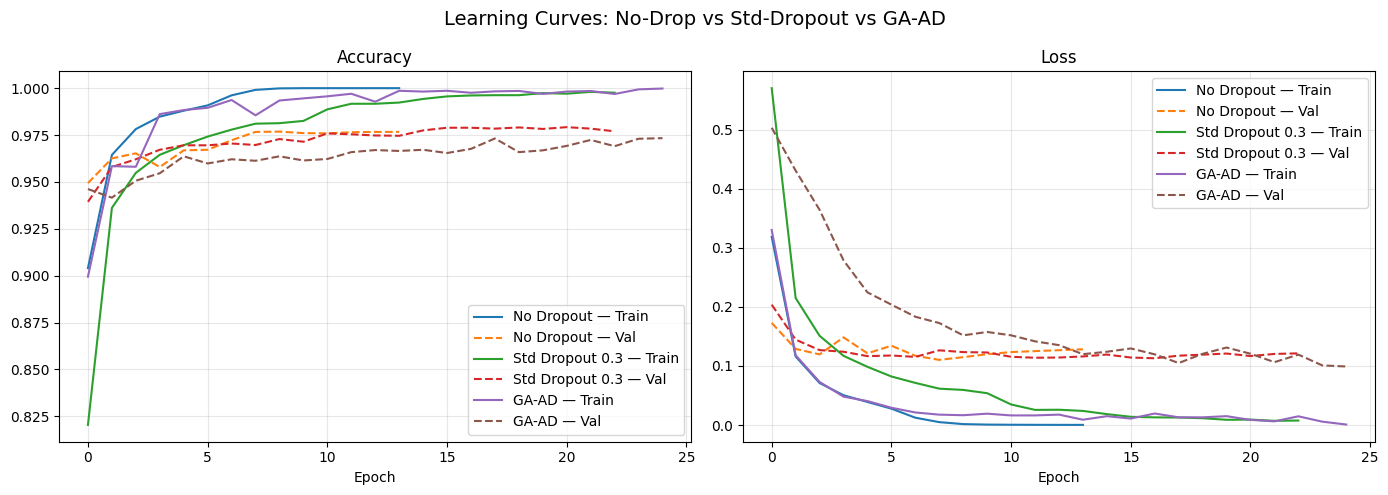

In [21]:
def plot_histories(histories, titles):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for hist, title in zip(histories, titles):
        # handle both keras History and our dict
        if hasattr(hist, 'history'):
            h = hist.history
        else:
            h = hist
        axes[0].plot(h['accuracy'], label=f'{title} — Train')
        axes[0].plot(h['val_accuracy'], label=f'{title} — Val', linestyle='--')
        axes[1].plot(h['loss'], label=f'{title} — Train')
        axes[1].plot(h['val_loss'], label=f'{title} — Val', linestyle='--')
    axes[0].set_title('Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[1].set_title('Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    plt.suptitle('Learning Curves: No-Drop vs Std-Dropout vs GA-AD', fontsize=14)
    plt.tight_layout()
    plt.show()

plot_histories(
    [history_no_drop, history_std_drop, history_gaad],
    ['No Dropout', 'Std Dropout 0.3', 'GA-AD']
)


## 13. Quantitative Evaluation on Held-out Test Set


\n### HELD-OUT TEST SET RESULTS
\n============================================================\n  No Dropout (Test)\n============================================================
Accuracy : 0.9771
Precision (macro): 0.9771
Recall (macro): 0.9767
F1-score : 0.9768
              precision    recall  f1-score   support

           0     0.9776    0.9839    0.9807       620
           1     0.9901    0.9943    0.9922       703
           2     0.9793    0.9793    0.9793       627
           3     0.9721    0.9617    0.9669       653
           4     0.9900    0.9771    0.9835       611
           5     0.9679    0.9525    0.9601       569
           6     0.9904    0.9935    0.9919       620
           7     0.9790    0.9879    0.9834       660
           8     0.9799    0.9622    0.9710       609
           9     0.9444    0.9745    0.9592       628

    accuracy                         0.9771      6300
   macro avg     0.9771    0.9767    0.9768      6300
weighted avg     0.9772    0.9771

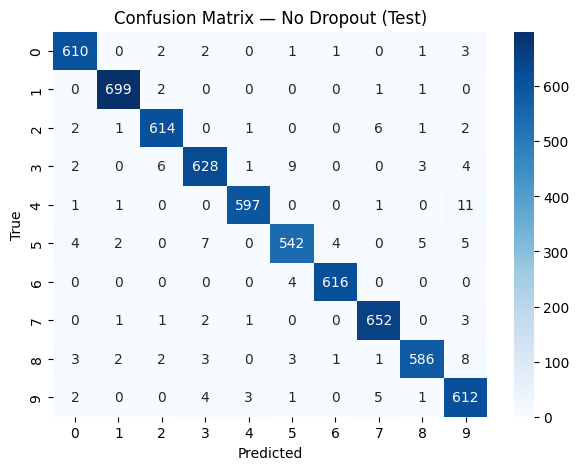

\n============================================================\n  Standard Dropout 0.3 (Test)\n============================================================
Accuracy : 0.9775
Precision (macro): 0.9774
Recall (macro): 0.9772
F1-score : 0.9773
              precision    recall  f1-score   support

           0     0.9807    0.9839    0.9823       620
           1     0.9887    0.9915    0.9901       703
           2     0.9777    0.9809    0.9793       627
           3     0.9708    0.9678    0.9693       653
           4     0.9851    0.9722    0.9786       611
           5     0.9716    0.9631    0.9673       569
           6     0.9952    0.9935    0.9944       620
           7     0.9862    0.9742    0.9802       660
           8     0.9785    0.9737    0.9761       609
           9     0.9399    0.9713    0.9554       628

    accuracy                         0.9775      6300
   macro avg     0.9774    0.9772    0.9773      6300
weighted avg     0.9776    0.9775    0.9775      6300



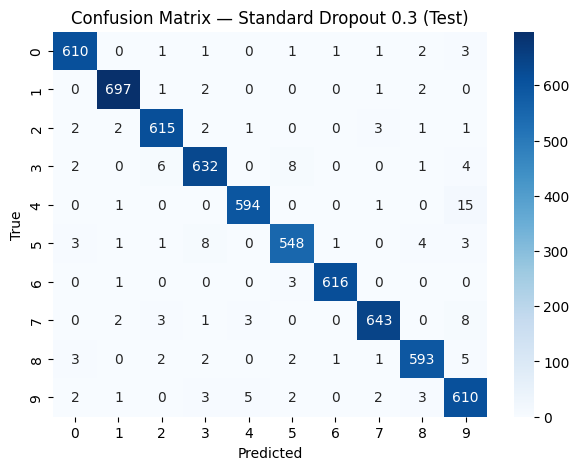

\n============================================================\n  Random-mask (Test)\n============================================================
Accuracy : 0.9705
Precision (macro): 0.9706
Recall (macro): 0.9702
F1-score : 0.9703
              precision    recall  f1-score   support

           0     0.9823    0.9823    0.9823       620
           1     0.9682    0.9957    0.9818       703
           2     0.9759    0.9681    0.9720       627
           3     0.9589    0.9648    0.9618       653
           4     0.9882    0.9574    0.9726       611
           5     0.9418    0.9666    0.9540       569
           6     0.9824    0.9903    0.9863       620
           7     0.9890    0.9515    0.9699       660
           8     0.9765    0.9573    0.9668       609
           9     0.9426    0.9682    0.9552       628

    accuracy                         0.9705      6300
   macro avg     0.9706    0.9702    0.9703      6300
weighted avg     0.9708    0.9705    0.9705      6300



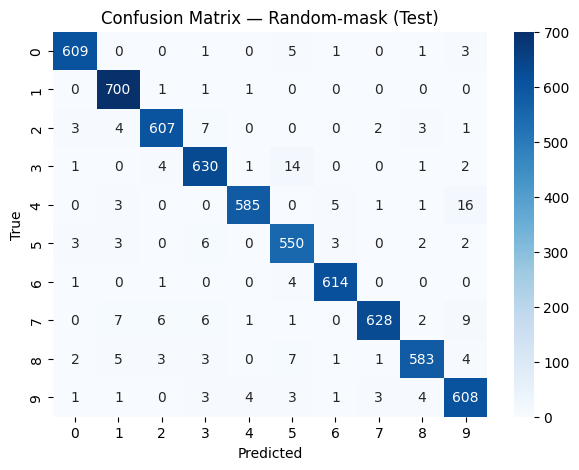

\n============================================================\n  Q-guided (Test)\n============================================================
Accuracy : 0.9706
Precision (macro): 0.9703
Recall (macro): 0.9705
F1-score : 0.9703
              precision    recall  f1-score   support

           0     0.9822    0.9806    0.9814       620
           1     0.9900    0.9844    0.9872       703
           2     0.9746    0.9777    0.9761       627
           3     0.9748    0.9464    0.9604       653
           4     0.9752    0.9673    0.9712       611
           5     0.9493    0.9543    0.9518       569
           6     0.9778    0.9952    0.9864       620
           7     0.9831    0.9667    0.9748       660
           8     0.9593    0.9672    0.9632       609
           9     0.9366    0.9650    0.9506       628

    accuracy                         0.9706      6300
   macro avg     0.9703    0.9705    0.9703      6300
weighted avg     0.9708    0.9706    0.9707      6300



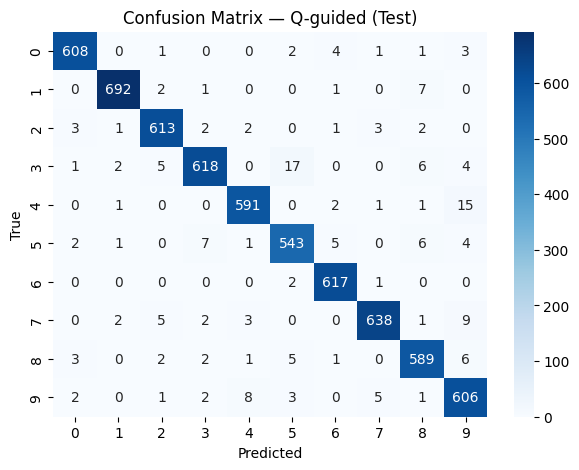

\n============================================================\n  GA elite-resampling (Test)\n============================================================
Accuracy : 0.9754
Precision (macro): 0.9755
Recall (macro): 0.9748
F1-score : 0.9751
              precision    recall  f1-score   support

           0     0.9823    0.9855    0.9839       620
           1     0.9872    0.9900    0.9886       703
           2     0.9762    0.9793    0.9777       627
           3     0.9562    0.9694    0.9627       653
           4     0.9849    0.9640    0.9744       611
           5     0.9798    0.9367    0.9578       569
           6     0.9794    0.9968    0.9880       620
           7     0.9732    0.9909    0.9820       660
           8     0.9737    0.9721    0.9729       609
           9     0.9618    0.9634    0.9626       628

    accuracy                         0.9754      6300
   macro avg     0.9755    0.9748    0.9751      6300
weighted avg     0.9755    0.9754    0.9753      6300



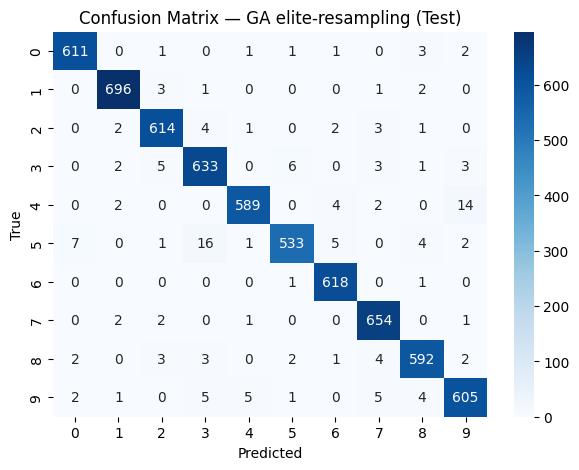

In [22]:
def evaluate_model(model_or_trainer, X, y_true_cat, model_name, is_custom=False):
    if is_custom:
        loss, acc = model_or_trainer._evaluate(X, y_true_cat)
        preds = []
        for i in range(0, len(X), 512):
            logits = model_or_trainer._forward(tf.constant(X[i:i+512]), training=False)
            preds.extend(np.argmax(logits.numpy(), axis=1))
        y_pred = np.asarray(preds)
    else:
        y_prob = model_or_trainer.predict(X, verbose=0)
        y_pred = np.argmax(y_prob, axis=1)
        acc = accuracy_score(np.argmax(y_true_cat, axis=1), y_pred)

    y_true = np.argmax(y_true_cat, axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0
    )
    print(f"\\n{'='*60}\\n  {model_name}\\n{'='*60}")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision (macro): {precision:.4f}")
    print(f"Recall (macro): {recall:.4f}")
    print(f"F1-score : {f1:.4f}")
    print(classification_report(y_true, y_pred, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(10), yticklabels=range(10))
    plt.title(f'Confusion Matrix — {model_name}')
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.show()
    return {'accuracy': acc, 'precision_macro': precision,
            'recall_macro': recall, 'f1_macro': f1}

print("\\n### HELD-OUT TEST SET RESULTS")
res_no = evaluate_model(model_no_drop, X_test, y_test, "No Dropout (Test)")
res_std = evaluate_model(model_std_drop, X_test, y_test, "Standard Dropout 0.3 (Test)")
res_random = evaluate_model(trainer_random, X_test, y_test, "Random-mask (Test)", is_custom=True)
res_q = evaluate_model(trainer_qguided, X_test, y_test, "Q-guided (Test)", is_custom=True)
res_ga = evaluate_model(trainer, X_test, y_test, "GA elite-resampling (Test)", is_custom=True)


In [23]:
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)'],
    'No Dropout': [res_no['accuracy'], res_no['precision_macro'], res_no['recall_macro'], res_no['f1_macro']],
    'Std Dropout 0.3': [res_std['accuracy'], res_std['precision_macro'], res_std['recall_macro'], res_std['f1_macro']],
    'Random-mask': [res_random['accuracy'], res_random['precision_macro'], res_random['recall_macro'], res_random['f1_macro']],
    'Q-guided': [res_q['accuracy'], res_q['precision_macro'], res_q['recall_macro'], res_q['f1_macro']],
    'GA elite-resampling': [res_ga['accuracy'], res_ga['precision_macro'], res_ga['recall_macro'], res_ga['f1_macro']]
}).round(4)
display(comparison)


,Metric,No Dropout,Std Dropout 0.3,Random-mask,Q-guided,GA elite-resampling
0,Accuracy,0.9771,0.9775,0.9705,0.9706,0.9754
1,Precision (macro),0.9771,0.9774,0.9706,0.9703,0.9755
2,Recall (macro),0.9767,0.9772,0.9702,0.9705,0.9748
3,F1 (macro),0.9768,0.9773,0.9703,0.9703,0.9751


## 14. Research Discussion

### Methodological changes
- **Importance score:** EMA of mean `|activation × ∂L/∂activation|`; this is a first-order saliency proxy rather than EMA change of a signed batch-mean gradient.
- **Module B removed:** the previous polynomial descriptor was a deterministic transform of the same score and did not provide independent information.
- **Q semantics:** high Q means protect; low Q means drop. The experiment should also test the reverse direction as a dedicated ablation before making claims.
- **Mask fitness:** GA no longer optimizes validation loss. It searches fixed-cardinality masks using retained importance only; this is a heuristic objective, not a validated generalization objective.
- **Stochasticity:** the GA returns a diverse elite pool and a different elite is sampled for each minibatch, avoiding one fixed “best” subnetwork.
- **Controls:** random-mask, Q-guided, and GA elite-resampling use the same target dropout rate and training protocol.
- **Data separation:** train, GA holdout, early-stopping validation, and final test are distinct. GA holdout is diagnostic only.
- **Training loop:** uses `range(0, n, batch_size)`, so the final partial batch is not skipped.
- **Rate selection:** `search_dropout_rate` provides a proper outer-loop interface: each candidate p must train a fresh model and is selected by early-stopping validation loss. Do not select p on test data.

### Important interpretation
This notebook is a corrected research prototype, not evidence that GA dropout outperforms standard dropout. The GA's importance-retention fitness can still behave like structured pruning; per-step elite resampling introduces stochasticity but does not by itself establish a regularization benefit. The decisive experiment is whether Q-guided sampling improves over uniform random masking at approximately the same compute cost. GA should be retained only if it adds measurable benefit beyond Q-guided sampling.

### Required ablations
1. Random mask versus Q-guided low-Q dropout versus reverse high-Q dropout.
2. Mean absolute gradient versus `|activation × gradient|`.
3. GA elite resampling versus single best mask versus Q-guided sampling.
4. Fixed p=0.30 versus a fully trained outer-loop grid over `P_GRID`.
5. Multiple seeds with paired comparisons and confidence intervals.
6. Record wall-clock time, number of candidate masks, and validation/test metrics.

### Limitations
- The provided `search_dropout_rate` is an interface and must be run separately for each p; it is not automatically executed in the main comparison.
- The GA holdout is currently reserved for post-training diagnostics, not used for candidate fine-tuning.
- The test set must be evaluated only after all design choices are frozen.
- One seed is insufficient for a publication-level claim.


## 15. Conclusion

The revised MNIST implementation addresses the main methodological problems identified in the review:
- Independent train, GA-holdout, early-stopping validation, and final test partitions.
- A corrected activation-gradient importance score.
- Removal of the redundant polynomial derivative descriptor.
- No validation-loss-driven GA mask search or arbitrary `lambda` rate penalty.
- Random-mask and Q-guided controls alongside GA elite resampling.
- A stochastic elite mask is sampled per minibatch.
- All minibatches, including the final partial batch, contribute optimizer updates.
- A proper outer-loop p-search interface is provided.

The results must be interpreted empirically. In particular, GA must demonstrate an advantage over the cheaper Q-guided control under matched compute budgets and repeated seeds before claiming improved generalization.